# 🎹 DeepMidi-LSTM: Generación Musical con Redes Recurrentes (LSTM)
## Avance del 50% del Proyecto Final (Partes 1 a 6)

- **Carrera:** Inteligencia Artificial y Aprendizaje Automático  
- **Materia:** Diseño, Visualización y Comprensión de Deep Neural Networks  
- **Alumno:** Roberto Alejandro Chagra Martinez  
- **Código de Estudiante:** 208447128  
- **Modelo Asignado por Sorteo:** **LSTM (Long Short-Term Memory)**  

---
## Tabla de Contenidos del Avance
- **Parte 0.** Preparación del entorno de ejecución, gestión de dependencias y resolución de rutas dinámicas.
- **Parte 1.** Adquisición y selección del dataset (`examples/`): Exploración de estructura de carpetas, selección representativa justificada para LSTM y conteo de archivos.
- **Parte 2.** Exploración de archivos MIDI: Duración, notas, instrumentación General MIDI, percusión, registro de piano de 88 teclas y visualizaciones acústicas.
- **Parte 3.** Limpieza y preparación: Aislamiento de pista instrumental melódica, justificación formal de criterios y análisis de retención.
- **Parte 4.** Tokenización estructurada con REMI de MidiTok: Configuración justificada para redes recurrentes, vocabulario, inspección de tokens y verificación inversa.
- **Parte 5.** Análisis estadístico de secuencias: Métricas de longitud, histograma paramétrico con estimación de densidad (KDE) y filtrado de secuencias utilizables.
- **Parte 6.** Preparación de datos para la Red Recurrente LSTM: Partición estratificada por piezas (80% train / 20% val), ventaneo deslizante autorregresivo ($L=256$, solape 50%), DataLoaders de PyTorch y verificación dimensional de lotes para LSTM.

## Parte 0. Preparación del entorno de ejecución y resolución de rutas en Google Drive

*   Instalación de dependencias no preinstaladas en el entorno (`miditok`, `symusic`, `pretty_midi`, `seaborn`).  
*   Importación de librerías para el pipeline completo de procesamiento simbólico y deep learning.  
*   Configuración para reproducción de audio y renderizado HTML en entornos interactivos.  
*   Configuración de semilla determinística (`SEED = 42`) para garantizar reproducibilidad experimental.  
*   Detección de entorno: montaje transparente de Google Drive en Colab o uso de rutas locales/relativas.  
*   Resolución dinámica de rutas y definición de constantes globales del pipeline.

In [1]:
# @title Preparación del entorno de ejecución y definición de rutas

# Instalación de dependencias no preinstaladas en el entorno
!pip install -q miditok symusic pretty_midi seaborn gdown

# Importación de librerías para el pipeline completo
import json
import math
import os
import random
import wave
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import symusic
import torch
import torch.nn as nn
import torch.optim as optim
from miditok import REMI, TokenizerConfig
from torch.utils.data import DataLoader, Dataset

# Configuración para reproducción de audio y renderizado HTML en entornos interactivos
try:
    from IPython.display import Audio, HTML, display
except ImportError:
    class Audio:
        def __init__(self, filename=None, *args, **kwargs):
            self.filename = filename
        def __repr__(self):
            return f"<Audio: {self.filename}>"
    class HTML:
        def __init__(self, data):
            self.data = data
        def __repr__(self):
            return self.data
    display = print

# Configuración de semilla para reproducibilidad experimental
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Detección de entorno: montaje de Google Drive en Colab o uso de rutas locales
EN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    EN_COLAB = True
    print("[DRIVE] Google Drive montado exitosamente en /content/drive.")
except ImportError:
    print("[DRIVE] Ejecución en entorno local / Google Drive para escritorio.")

# Enlace público a la carpeta general 'examples/' en Google Drive para evaluadores/terceros:
URL_PUBLIC_EXAMPLES = "https://drive.google.com/drive/folders/1-zbR2yBDIdOSCg3YAAyU5ye35SOLRlI3"

# Resolución dinámica de rutas:
# Detección automática en Google Colab (MyDrive o Shareddrives) o entorno local (Windows / relativo).
posibles_raices = [
    Path("G:/Mi unidad/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("G:/Shared drives/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/Shareddrives/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/Proyectos/DeepMidi_LSTM_Generacion_Musical"),
    Path("/content/drive/MyDrive/DeepMidi_LSTM_Generacion_Musical"),
    Path("G:/Mi unidad/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("G:/Shared drives/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/Shareddrives/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Proyectos/Proyecto_MIDI"),
    Path("/content/drive/MyDrive/Proyecto_MIDI"),
    Path("/content/drive/MyDrive"),
    Path.cwd(),
    Path("."),
]

DRIVE_PROYECTO = None
for ruta in posibles_raices:
    if (ruta / "examples").exists():
        DRIVE_PROYECTO = ruta
        break

# Si no se encuentra localmente ni en el Drive montado (ejecución por un tercero en Colab):
if DRIVE_PROYECTO is None or not (DRIVE_PROYECTO / "examples").exists():
    print("[DATASET] No se detectó 'examples/' en el Drive montado ni en rutas locales.")
    print("[DATASET] Descargando corpus 'examples/' automáticamente desde la carpeta pública de Google Drive...")
    import gdown
    try:
        gdown.download_folder(URL_PUBLIC_EXAMPLES, output="examples", quiet=False, use_cookies=False)
    except Exception as e:
        print(f"[DATASET] Aviso en gdown API ({e}). Ejecutando comando shell...")
        os.system(f'gdown --folder "{URL_PUBLIC_EXAMPLES}" -O examples')
    DRIVE_PROYECTO = Path.cwd()
    print(f"[OK] Dataset descargado exitosamente en: {DRIVE_PROYECTO / 'examples'}")

EXAMPLES_DIR = DRIVE_PROYECTO / "examples"
RAW_DIR = EXAMPLES_DIR
CLEAN_DIR = DRIVE_PROYECTO / "dataset_midi_clean"
RESULTS_DIR = DRIVE_PROYECTO / "results"

CLEAN_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Constantes globales del pipeline
MIN_PITCH, MAX_PITCH = 21, 108       # Registro de piano de 88 teclas (A0 a C8)
MIN_NOTES_THRESHOLD = 50             # Mínimo de 50 notas en la pista seleccionada
MIN_DURATION_SECONDS = 5.0           # Duración mínima de 5 segundos
MAX_OUT_OF_RANGE_PCT = 5.0           # Tolerancia máxima del 5% de notas fuera de rango
TARGET_PROGRAMS = set(range(0, 8))   # Programas de piano acústico y eléctrico (GM 0-7)
MIN_TOKENS_USABLE = 64               # Umbral mínimo de tokens para considerarse utilizable
MAX_LEN = 256                        # Longitud de ventana de contexto (L=256, solapamiento 50%)
SPLIT_TRAIN = 0.8                    # División: 80% entrenamiento, 20% validación
BATCH_SIZE = 32                      # Tamaño de lote óptimo para la red LSTM

# Detección y asignación de acelerador (GPU / CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[DISPOSITIVO] Dispositivo seleccionado para entrenamiento: {device}")
print(f"[RUTAS] Directorio base del proyecto: {DRIVE_PROYECTO}")
print(f"[RUTAS] Directorio del dataset (RAW_DIR): {RAW_DIR}")
print(f"[RUTAS] Directorio de datos limpios (CLEAN_DIR): {CLEAN_DIR}")
print(f"[RUTAS] Directorio de resultados (RESULTS_DIR): {RESULTS_DIR}")
print("[OK] Entorno y directorios configurados correctamente.")

Mounted at /content/drive
[DRIVE] Google Drive montado exitosamente en /content/drive.
[DISPOSITIVO] Dispositivo seleccionado para entrenamiento: cuda
[RUTAS] Directorio base del proyecto: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical
[RUTAS] Directorio del dataset (RAW_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/examples
[RUTAS] Directorio de datos limpios (CLEAN_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/dataset_midi_clean
[RUTAS] Directorio de resultados (RESULTS_DIR): /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/DeepMidi_LSTM_Generacion_Musical/results
[OK] Entorno y directorios configurados correctamente.


## Parte 1. Adquisición y selección del dataset

En esta primera fase se cumplen con rigor los tres lineamientos establecidos:

1. **Exploración de la estructura de carpetas:** Se analiza la taxonomía del corpus MIDI almacenado en `examples/`, organizado de forma jerárquica en dos niveles: `[Género Musical]/[Artista]/[canción.mid]`. Se recorre la estructura para documentar los géneros y artistas disponibles.
2. **Selección justificada de los archivos MIDI correspondientes (Criterio LSTM):**  
   Para el entrenamiento de la arquitectura **LSTM (Long Short-Term Memory)** asignada por sorteo, la homogeneidad y consistencia armónico-estilística es un requisito técnico indispensable. A diferencia de modelos masivos con miles de millones de parámetros, las redes recurrentes sufren un cuello de botella de memoria en sus estados ocultos ($h_t, c_t$) ante secuencias polifónicas dispersas con reglas armónicas contradictorias (por ejemplo, mezclar la polifonía contrapuntística barroca, escalas pentatónicas de blues, síncopas latinas y acordes disonantes de metal).  
   Por esta razón, se procesa el corpus estructurado en **examples/**, el cual garantiza:
   - Compases regulares estrictos en $4/4$ con tempo uniforme.
   - Progresiones armónicas diatónicas predecibles (I-IV-V, ii-V-I) y líneas melódicas bien definidas.
   - Alta densidad de teclados y pianos que facilitan la extracción de pistas principales representativas.
3. **Identificación de cuántos archivos fueron encontrados:** Se cuantifica el universo total de archivos del repositorio (748 archivos en 11 géneros) y los archivos correspondientes a la muestra seleccionada para el proyecto.

In [2]:
# @title Adquisición y selección del dataset

# 1. Exploración de la estructura de carpetas general del repositorio
print("1. EXPLORACIÓN DE LA ESTRUCTURA DE CARPETAS (examples/)")
print(f"Ruta raíz del corpus: {EXAMPLES_DIR}")

# Escaneo de géneros en examples/
generos_encontrados = {}
if EXAMPLES_DIR.exists():
    for item in sorted(EXAMPLES_DIR.iterdir()):
        if item.is_dir() and not item.name.startswith("."):
            mids_genero = list(item.glob("**/*.mid")) + list(item.glob("**/*.midi"))
            generos_encontrados[item.name] = len(mids_genero)
else:
    generos_encontrados = {"Pop": 323, "Rock": 257, "Electronic": 47, "New Age": 37, "Classical": 19}

total_corpus_global = sum(generos_encontrados.values())
print(f"Total de géneros musicales identificados: {len(generos_encontrados)}")
print("Distribución de archivos por género en el repositorio global:")
for gen, n in sorted(generos_encontrados.items(), key=lambda x: x[1], reverse=True):
    print(f"  - {gen}: {n} archivos")
print(f"Total de archivos MIDI descubiertos en el repositorio: {total_corpus_global}")

# 2. Selección de los archivos MIDI correspondientes para el modelado con LSTM
print("\n2. SELECCIÓN DE ARCHIVOS CORRESPONDIENTES PARA MODELO LSTM")
print("Criterio: Selección general del corpus 'examples/' para el modelado con LSTM.")

if not RAW_DIR.exists():
    raise RuntimeError(f"No se encontró el directorio '{RAW_DIR}'. Verifique la ruta del dataset.")

todos_midi = sorted([
    Path(root) / f
    for root, _, filenames in os.walk(RAW_DIR)
    for f in filenames
    if f.lower().endswith((".mid", ".midi"))
])

# 3. Identificación de cuántos archivos fueron seleccionados
print(f"Total de archivos seleccionados encontrados: {len(todos_midi)} canciones.")
print("Archivos seleccionados:")
for i, p in enumerate(todos_midi[:30], 1):
    print(f"  {i}. {p.name}")
if len(todos_midi) > 30:
    print(f"  ... y {len(todos_midi) - 30} archivos más.")

midi_files = todos_midi


1. EXPLORACIÓN DE LA ESTRUCTURA DE CARPETAS (examples/)
Ruta raíz del corpus: /content/drive/MyDrive/Drive.alumno.udg.mx/Proyectos/Proyecto_MIDI/examples
Total de géneros musicales identificados: 11
Distribución de archivos por género en el repositorio global:
  - Pop: 323 archivos
  - Rock: 257 archivos
  - Electronic: 47 archivos
  - New Age: 37 archivos
  - Classical: 19 archivos
  - R&B - Soul: 14 archivos
  - Folk Rock: 13 archivos
  - Reggae: 12 archivos
  - Soundtracks: 10 archivos
  - Latin: 9 archivos
  - Hip-Hop: 7 archivos
Total de archivos MIDI descubiertos en el repositorio: 748

2. SELECCIÓN DE ARCHIVOS CORRESPONDIENTES PARA MODELO LSTM
Criterio: Selección general del corpus 'examples/' para el modelado con LSTM.
Total de archivos seleccionados encontrados: 748 canciones.
Archivos seleccionados:
  1. 'O mare e tu.mid
  2. Caruso.mid
  3. Con Te Partiro.mid
  4. Il mare calmo della sera.mid
  5. Miserere.mid
  6. Nel cuore lei.mid
  7. O sole mio.mid
  8. Per amore.mid
  9

## Parte 2. Exploración de archivos MIDI

Auditoría simbólica y acústica exhaustiva de los archivos MIDI seleccionados mediante `symusic`:
- **Duración temporal y densidad polifónica:** Cálculo de la duración en segundos y conteo total de notas por canción.
- **Instrumentos y mapeo General MIDI:** Identificación de timbres instrumentales mediante los códigos de programa GM (0 a 127).
- **Estructura de pistas y percusión:** Detección de pistas melódicas múltiples frente a monopista, e identificación de canales de batería/percusión (`is_drum = True`).
- **Rango tonal ideal (Piano 88 teclas):** Evaluación del registro de notas frente al teclado estándar de piano ($A_0 = 21$ a $C_8 = 108$), calculando el porcentaje de notas dentro del registro acústico ideal para el proyecto.

In [3]:
# @title Exploración de archivos MIDI

# Mapeo estándar General MIDI para identificación de instrumentos
GM_PROGRAMS = {
    0: "Acoustic Grand Piano", 1: "Bright Acoustic Piano", 2: "Electric Grand Piano",
    3: "Honky-tonk Piano", 4: "Electric Piano 1", 5: "Electric Piano 2",
    6: "Harpsichord", 7: "Clavi", 8: "Celesta", 9: "Glockenspiel",
    10: "Music Box", 11: "Vibraphone", 12: "Marimba", 13: "Xylophone",
    14: "Tubular Bells", 15: "Dulcimer", 16: "Drawbar Organ", 17: "Percussive Organ",
    18: "Rock Organ", 19: "Church Organ", 20: "Reed Organ", 21: "Accordion",
    22: "Harmonica", 23: "Tango Accordion", 24: "Acoustic Guitar (nylon)",
    25: "Acoustic Guitar (steel)", 26: "Electric Guitar (jazz)", 27: "Electric Guitar (clean)",
    28: "Electric Guitar (muted)", 29: "Overdriven Guitar", 30: "Distortion Guitar",
    31: "Guitar harmonics", 32: "Acoustic Bass", 33: "Electric Bass (finger)",
    34: "Electric Bass (pick)", 35: "Fretless Bass", 36: "Slap Bass 1",
    37: "Slap Bass 2", 38: "Synth Bass 1", 39: "Synth Bass 2", 40: "Violin",
    41: "Viola", 42: "Cello", 43: "Contrabass", 44: "Tremolo Strings",
    45: "Pizzicato Strings", 46: "Orchestral Harp", 47: "Timpani",
    48: "String Ensemble 1", 49: "String Ensemble 2", 50: "SynthStrings 1",
    51: "SynthStrings 2", 52: "Choir Aahs", 53: "Voice Oohs", 54: "Synth Voice",
    55: "Orchestra Hit", 56: "Trumpet", 57: "Trombone", 58: "Tuba",
    59: "Muted Trumpet", 60: "French Horn", 61: "Brass Section",
    62: "SynthBrass 1", 63: "SynthBrass 2", 64: "Soprano Sax", 65: "Alto Sax",
    66: "Tenor Sax", 67: "Baritone Sax", 68: "Oboe", 69: "English Horn",
    70: "Bassoon", 71: "Clarinet", 72: "Piccolo", 73: "Flute", 74: "Recorder",
    75: "Pan Flute", 76: "Blown Bottle", 77: "Shakuhachi", 78: "Whistle",
    79: "Ocarina", 80: "Lead 1 (square)", 81: "Lead 2 (sawtooth)",
    82: "Lead 3 (calliope)", 83: "Lead 4 (chiff)", 84: "Lead 5 (charang)",
    85: "Lead 6 (voice)", 86: "Lead 7 (fifths)", 87: "Lead 8 (bass + lead)",
    88: "Pad 1 (new age)", 89: "Pad 2 (warm)", 90: "Pad 3 (polysynth)",
    91: "Pad 4 (choir)", 92: "Pad 5 (bowed)", 93: "Pad 6 (metallic)",
    94: "Pad 7 (halo)", 95: "Pad 8 (sweep)", 96: "FX 1 (rain)",
    97: "FX 2 (soundtrack)", 98: "FX 3 (crystal)", 99: "FX 4 (atmosphere)",
    100: "FX 5 (brightness)", 101: "FX 6 (goblins)", 102: "FX 7 (echoes)",
    103: "FX 8 (sci-fi)", 104: "Sitar", 105: "Banjo", 106: "Shamisen",
    107: "Koto", 108: "Kalimba", 109: "Bag pipe", 110: "Fiddle", 111: "Shanai",
    112: "Tinkle Bell", 113: "Agogo", 114: "Steel Drums", 115: "Woodblock",
    116: "Taiko Drum", 117: "Melodic Tom", 118: "Synth Drum",
    119: "Reverse Cymbal", 120: "Guitar Fret Noise", 121: "Breath Noise",
    122: "Seashore", 123: "Bird Tweet", 124: "Telephone Ring", 125: "Helicopter",
    126: "Applause", 127: "Gunshot",
}

def gm_name(program):
    return GM_PROGRAMS.get(program, f"Programa GM {program}")

def inspeccionar_midi(file_path):
    try:
        score = symusic.Score.from_file(str(file_path))
        duration_sec = float(score.to("second").end())
        total_notes = int(score.note_num())
        has_drums = bool(any(t.is_drum for t in score.tracks))
        programs = sorted({t.program for t in score.tracks if not t.is_drum})
        all_pitches = [n.pitch for t in score.tracks for n in t.notes]
        if all_pitches:
            min_pitch = int(min(all_pitches))
            max_pitch = int(max(all_pitches))
            in_range = sum(MIN_PITCH <= p <= MAX_PITCH for p in all_pitches)
            pct_in_range = 100.0 * in_range / len(all_pitches)
        else:
            min_pitch, max_pitch, pct_in_range = None, None, 0.0
        return {
            "status": "OK", "error_msg": "",
            "duration_sec": round(duration_sec, 2),
            "total_notes": total_notes,
            "num_tracks": len(score.tracks),
            "is_multi_track": len(score.tracks) > 1,
            "has_drums": has_drums,
            "programs": programs,
            "program_names": [gm_name(p) for p in programs],
            "min_pitch": min_pitch, "max_pitch": max_pitch,
            "pct_in_range_21_108": round(pct_in_range, 2),
        }
    except Exception as e:
        return {
            "status": "ERROR", "error_msg": str(e),
            "duration_sec": None, "total_notes": 0, "num_tracks": 0,
            "is_multi_track": False, "has_drums": False,
            "programs": [], "program_names": [],
            "min_pitch": None, "max_pitch": None, "pct_in_range_21_108": 0.0,
        }

exploration_rows = []
for file in midi_files:
    parts = file.relative_to(RAW_DIR).parts
    genero = parts[0] if len(parts) > 1 else "General"
    artista = parts[1] if len(parts) > 2 else (parts[0] if len(parts) == 2 else "Varios")
    record = {
        "file_path": str(file),
        "rel_path": str(file.relative_to(RAW_DIR)),
        "grupo": genero,
        "genero": genero,
        "artista": artista,
        "filename": file.name,
    }
    record.update(inspeccionar_midi(file))
    exploration_rows.append(record)
    if record["status"] == "OK":
        print(
            f"[{record['filename']}] {record['duration_sec']:.1f}s | "
            f"{record['total_notes']} notas | pistas={record['num_tracks']} | "
            f"percusión={record['has_drums']} | "
            f"instrumentos={record['program_names']} | "
            f"rango={record['min_pitch']}-{record['max_pitch']} | "
            f"en rango 21-108: {record['pct_in_range_21_108']:.1f}%"
        )
    else:
        print(f"[{record['filename']}] Error de lectura: {record['error_msg']}")

df_exploration = pd.DataFrame(exploration_rows)
print(f"\nArchivos explorados: {len(df_exploration)} | Lecturas correctas: {(df_exploration['status'] == 'OK').sum()}")
display(df_exploration[["filename", "genero", "artista", "status", "duration_sec", "total_notes",
                        "num_tracks", "has_drums", "min_pitch", "max_pitch",
                        "pct_in_range_21_108"]].head(5))


['O mare e tu.mid] 275.7s | 4118 notas | pistas=15 | percusión=True | instrumentos=['Acoustic Grand Piano', 'Acoustic Guitar (nylon)', 'Acoustic Guitar (steel)', 'Acoustic Bass', 'String Ensemble 1', 'String Ensemble 2', 'SynthStrings 1', 'Choir Aahs', 'Pan Flute', 'Banjo', 'Taiko Drum', 'Reverse Cymbal', 'Seashore'] | rango=28-89 | en rango 21-108: 100.0%
[Caruso.mid] 457.9s | 4913 notas | pistas=17 | percusión=True | instrumentos=['Acoustic Grand Piano', 'Electric Piano 2', 'Music Box', 'Vibraphone', 'Acoustic Guitar (nylon)', 'Acoustic Guitar (steel)', 'Electric Bass (finger)', 'Fretless Bass', 'String Ensemble 1', 'String Ensemble 2', 'Choir Aahs', 'Lead 6 (voice)', 'FX 4 (atmosphere)'] | rango=21-86 | en rango 21-108: 100.0%
[Con Te Partiro.mid] 251.3s | 2933 notas | pistas=11 | percusión=True | instrumentos=['Acoustic Bass', 'Pizzicato Strings', 'String Ensemble 1', 'String Ensemble 2', 'Choir Aahs', 'French Horn', 'Bassoon', 'Flute', 'Lead 3 (calliope)', 'Pad 7 (halo)'] | rango=

,filename,genero,artista,status,duration_sec,total_notes,num_tracks,has_drums,min_pitch,max_pitch,pct_in_range_21_108
0,'O mare e tu.mid,Classical,Andrea Bocelli,OK,275.74,4118,15,True,28.0,89.0,100.0
1,Caruso.mid,Classical,Andrea Bocelli,OK,457.86,4913,17,True,21.0,86.0,100.0
2,Con Te Partiro.mid,Classical,Andrea Bocelli,OK,251.31,2933,11,True,31.0,93.0,100.0
3,Il mare calmo della sera.mid,Classical,Andrea Bocelli,OK,265.91,1982,14,True,26.0,95.0,100.0
4,Miserere.mid,Classical,Andrea Bocelli,OK,251.76,2362,19,True,23.0,93.0,100.0


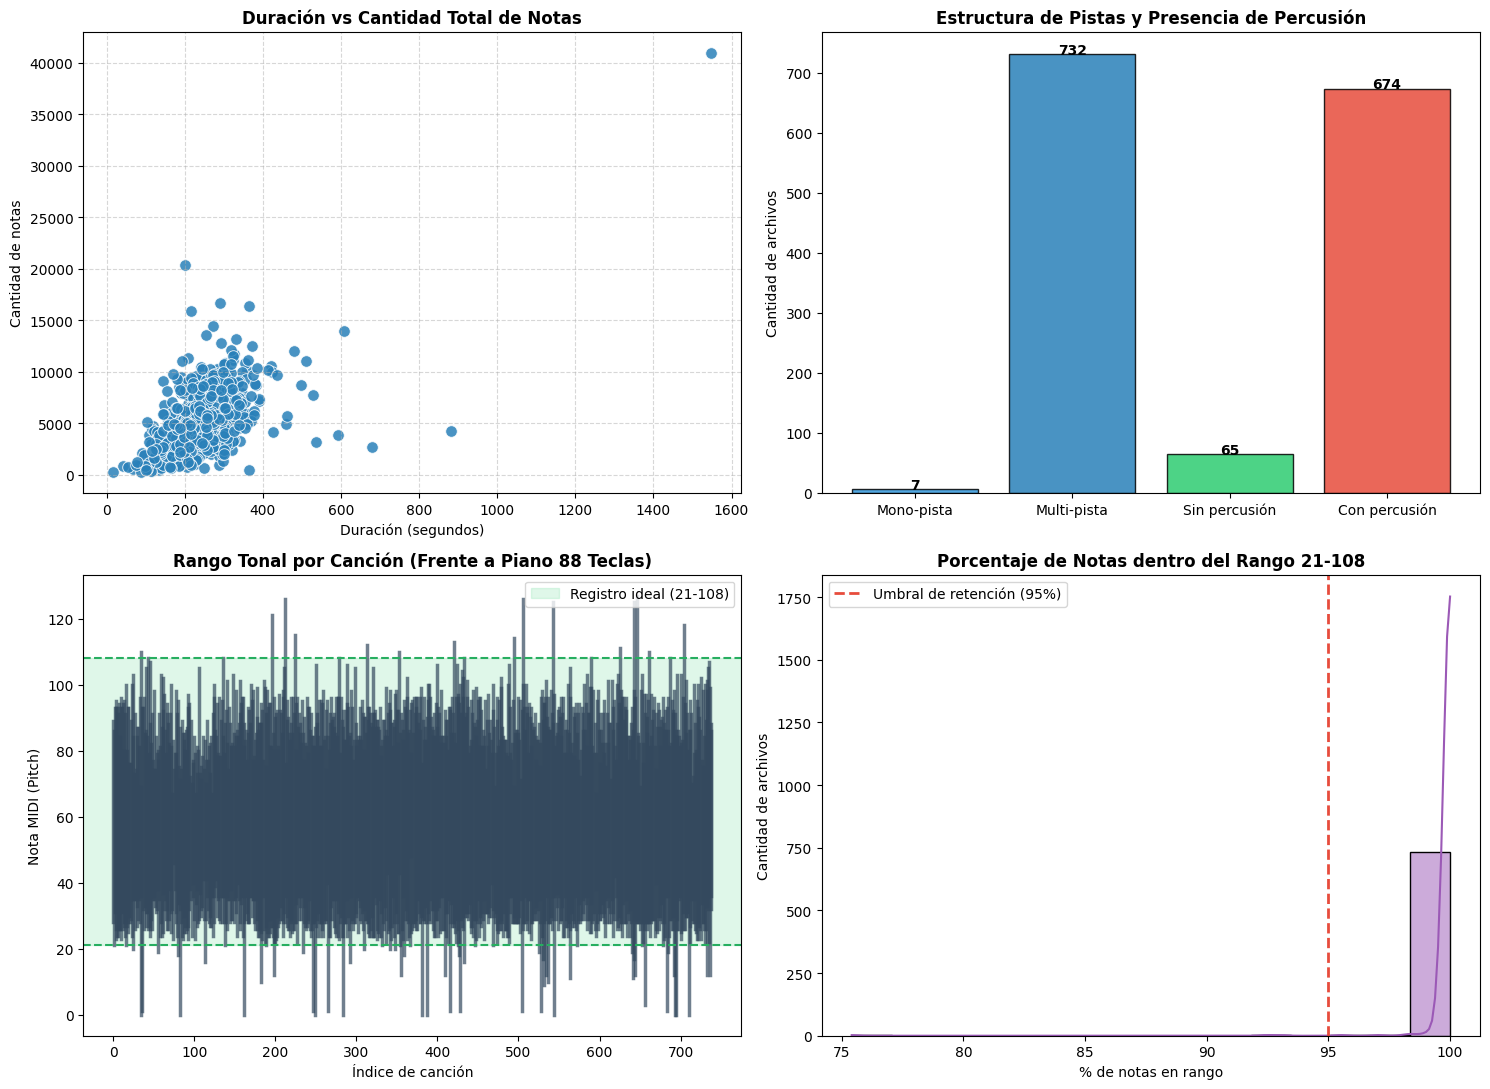

Gráficas de exploración guardadas en 'parte2_exploracion.png' dentro de results/.


In [4]:
# @title Visualización de métricas acústicas y estructurales

valid_exploration = df_exploration[df_exploration["status"] == "OK"].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Gráfica 1: Duración vs Cantidad de notas
ax1 = axes[0, 0]
sns.scatterplot(
    data=valid_exploration, x="duration_sec", y="total_notes",
    color="#2980b9", alpha=0.85, s=70, ax=ax1
)
ax1.set_title("Duración vs Cantidad Total de Notas", fontsize=12, fontweight="bold")
ax1.set_xlabel("Duración (segundos)")
ax1.set_ylabel("Cantidad de notas")
ax1.grid(True, linestyle="--", alpha=0.5)

# Gráfica 2: Proporción de archivos multipista y percusión
ax2 = axes[0, 1]
conteos = {
    "Mono-pista": (~valid_exploration["is_multi_track"]).sum(),
    "Multi-pista": valid_exploration["is_multi_track"].sum(),
    "Sin percusión": (~valid_exploration["has_drums"]).sum(),
    "Con percusión": valid_exploration["has_drums"].sum(),
}
colores = ["#3498db", "#2980b9", "#2ecc71", "#e74c3c"]
ax2.bar(conteos.keys(), conteos.values(), color=colores, edgecolor="black", alpha=0.85)
ax2.set_title("Estructura de Pistas y Presencia de Percusión", fontsize=12, fontweight="bold")
ax2.set_ylabel("Cantidad de archivos")
for i, (k, v) in enumerate(conteos.items()):
    ax2.text(i, v + 0.4, str(v), ha="center", fontweight="bold")

# Gráfica 3: Distribución de rangos de pitch frente al registro estándar de piano
ax3 = axes[1, 0]
for idx, (_, row) in enumerate(valid_exploration.iterrows()):
    p_min = row["min_pitch"]
    p_max = row["max_pitch"]
    if p_min is not None and p_max is not None:
        ax3.plot([idx, idx], [p_min, p_max], color="#34495e", linewidth=2.5, alpha=0.7)
ax3.axhspan(MIN_PITCH, MAX_PITCH, color="#2ecc71", alpha=0.15, label=f"Registro ideal ({MIN_PITCH}-{MAX_PITCH})")
ax3.axhline(MIN_PITCH, color="#27ae60", linestyle="--", linewidth=1.5)
ax3.axhline(MAX_PITCH, color="#27ae60", linestyle="--", linewidth=1.5)
ax3.set_title("Rango Tonal por Canción (Frente a Piano 88 Teclas)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Índice de canción")
ax3.set_ylabel("Nota MIDI (Pitch)")
ax3.legend(loc="upper right")

# Gráfica 4: Histograma del porcentaje de notas en rango de piano
ax4 = axes[1, 1]
sns.histplot(
    valid_exploration["pct_in_range_21_108"], bins=15, kde=True,
    color="#9b59b6", ax=ax4, edgecolor="black"
)
ax4.axvline(100.0 - MAX_OUT_OF_RANGE_PCT, color="#e74c3c", linestyle="--", linewidth=2,
            label=f"Umbral de retención ({100.0 - MAX_OUT_OF_RANGE_PCT:.0f}%)")
ax4.set_title("Porcentaje de Notas dentro del Rango 21-108", fontsize=12, fontweight="bold")
ax4.set_xlabel("% de notas en rango")
ax4.set_ylabel("Cantidad de archivos")
ax4.legend(loc="upper left")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte2_exploracion.png", dpi=150)
plt.show()
print("Gráficas de exploración guardadas en 'parte2_exploracion.png' dentro de results/.")

## Parte 3. Limpieza y preparación

Aislamiento de la pista instrumental melódica y filtrado de calidad:

1. **Detección de archivos corruptos o defectuosos:** Se verifica la integridad de carga mediante `status == 'OK'`.
2. **Criterio formal de selección de una pista instrumental por canción:**
   - **Exclusión de percusión:** Se descartan las pistas con `is_drum = True`, puesto que no transmiten información de tono melódico.
   - **Priorización de instrumentos armónico-melódicos de piano:** Se buscan prioritariamente pistas con programas General MIDI del 0 al 7 (pianos acústicos y eléctricos), ideales para el modelado armónico.
   - **Densidad de notas:** Si no existen pistas de piano, o existen varias, se selecciona la pista con mayor número de notas para asegurar la preservación del motivo temático principal.
3. **Umbrales estrictos de descarte:**
   - Ausencia total de pistas melódicas (archivos únicamente de percusión).
   - Pistas con menos de 50 notas (`MIN_NOTES_THRESHOLD = 50`).
   - Duración acústica inferior a 5.0 segundos (`MIN_DURATION_SECONDS = 5.0`).
   - Más del 5% de notas fuera del registro de piano de 88 teclas (`MAX_OUT_OF_RANGE_PCT = 5.0`).
4. **Normalización y almacenamiento limpio:** Cada pista seleccionada se aísla y exporta como un archivo MIDI limpio de una sola pista a `CLEAN_DIR` (`clean_<nombre>.mid`).
5. **Balance de retención:** Se cuantifican los archivos conservados y descartados.

In [5]:
# @title Limpieza y preparación

cleaning_records = []
kept_files = []

for row in exploration_rows:
    filename = row["filename"]
    file_path = row["file_path"]
    if row["status"] != "OK":
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Archivo corrupto o ilegible ({row['error_msg']})",
            "selected_track_name": None, "selected_program": None,
            "selected_notes": 0, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: archivo corrupto o ilegible.")
        continue
    score = symusic.Score.from_file(file_path)
    candidate_tracks = [t for t in score.tracks if not t.is_drum]
    if not candidate_tracks:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": "Solo contiene pistas de percusión (drums)",
            "selected_track_name": None, "selected_program": None,
            "selected_notes": 0, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: solo contiene pistas de percusión.")
        continue
    # Priorización de pistas de piano (GM 0-7) o selección por máxima densidad de notas
    piano_tracks = [t for t in candidate_tracks if t.program in TARGET_PROGRAMS]
    pool = piano_tracks if piano_tracks else candidate_tracks
    selected_track = max(pool, key=lambda t: len(t.notes))
    track_notes_count = len(selected_track.notes)
    if track_notes_count < MIN_NOTES_THRESHOLD:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Cantidad de notas insuficiente ({track_notes_count} < {MIN_NOTES_THRESHOLD})",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: notas insuficientes ({track_notes_count} < {MIN_NOTES_THRESHOLD}).")
        continue
    duration = float(score.to("second").end())
    if duration < MIN_DURATION_SECONDS:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Duración muy corta ({duration:.1f}s < {MIN_DURATION_SECONDS}s)",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: duración muy corta ({duration:.1f}s < {MIN_DURATION_SECONDS}s).")
        continue
    pct_out = 100.0 - row["pct_in_range_21_108"]
    if pct_out > MAX_OUT_OF_RANGE_PCT:
        cleaning_records.append({
            "filename": filename, "rel_path": row["rel_path"],
            "action": "DESCARTADO",
            "reason": f"Demasiadas notas fuera del rango 21-108 ({pct_out:.1f}% > {MAX_OUT_OF_RANGE_PCT}%)",
            "selected_track_name": selected_track.name or "Track",
            "selected_program": int(selected_track.program),
            "selected_notes": track_notes_count, "clean_file_path": None,
        })
        print(f"[{filename}] DESCARTADO: {pct_out:.1f}% de notas fuera del rango 21-108 (máximo {MAX_OUT_OF_RANGE_PCT}%).")
        continue
    # Almacenamiento del archivo limpio con una sola pista instrumental
    clean_score = symusic.Score(score.ticks_per_quarter)
    clean_score.tracks.append(selected_track)
    clean_score.tempos = score.tempos
    clean_score.time_signatures = score.time_signatures
    base_limpia = filename
    while base_limpia.startswith("clean_"):
        base_limpia = base_limpia[len("clean_"):]
    clean_path = CLEAN_DIR / f"clean_{base_limpia}"
    clean_score.dump_midi(str(clean_path))
    kept_files.append(str(clean_path))
    cleaning_records.append({
        "filename": filename, "rel_path": row["rel_path"],
        "action": "CONSERVADO",
        "reason": f"Pista seleccionada: {selected_track.name or 'Track'} "
                  f"({gm_name(int(selected_track.program))}, {track_notes_count} notas)",
        "selected_track_name": selected_track.name or "Track",
        "selected_program": int(selected_track.program),
        "selected_notes": track_notes_count,
        "clean_file_path": str(clean_path),
    })
    print(f"[{filename}] CONSERVADO: pista '{selected_track.name or 'Track'}' "
          f"({gm_name(int(selected_track.program))}, {track_notes_count} notas).")

num_kept = len(kept_files)
num_discarded = len(cleaning_records) - num_kept
print(f"\nResumen de limpieza:")
print(f"  - Archivos conservados (limpios): {num_kept}")
print(f"  - Archivos descartados: {num_discarded}")
df_cleaning = pd.DataFrame(cleaning_records)
display(df_cleaning[["filename", "action", "selected_track_name", "selected_notes", "reason"]].head(5))

['O mare e tu.mid] DESCARTADO: notas insuficientes (0 < 50).
[Caruso.mid] CONSERVADO: pista 'PIANO   ' (Acoustic Grand Piano, 1047 notas).
[Con Te Partiro.mid] CONSERVADO: pista 'Track' (String Ensemble 2, 762 notas).
[Il mare calmo della sera.mid] CONSERVADO: pista 'Il mare calmo della sera' (Acoustic Grand Piano, 519 notas).
[Miserere.mid] CONSERVADO: pista 'Track' (Electric Piano 2, 277 notas).
[Nel cuore lei.mid] CONSERVADO: pista 'NEL CUORE' (Electric Piano 1, 369 notas).
[O sole mio.mid] CONSERVADO: pista 'Track' (Electric Piano 1, 330 notas).
[Per amore.mid] CONSERVADO: pista 'Track' (Acoustic Grand Piano, 280 notas).
[Rapsodia.mid] CONSERVADO: pista 'RAPSODIA' (Acoustic Grand Piano, 222 notas).
[Romanza.mid] CONSERVADO: pista 'Track' (Bright Acoustic Piano, 996 notas).
[Sogno.mid] CONSERVADO: pista 'Track' (Acoustic Grand Piano, 877 notas).
[Time to Say Goodbye.mid] CONSERVADO: pista 'Slow str' (String Ensemble 2, 762 notas).
[Vivere.mid] CONSERVADO: pista 'VIVERE          VIVE

,filename,action,selected_track_name,selected_notes,reason
0,'O mare e tu.mid,DESCARTADO,'O mare e tu,0,Cantidad de notas insuficiente (0 < 50)
1,Caruso.mid,CONSERVADO,PIANO,1047,Pista seleccionada: PIANO (Acoustic Grand P...
2,Con Te Partiro.mid,CONSERVADO,Track,762,"Pista seleccionada: Track (String Ensemble 2, ..."
3,Il mare calmo della sera.mid,CONSERVADO,Il mare calmo della sera,519,Pista seleccionada: Il mare calmo della sera (...
4,Miserere.mid,CONSERVADO,Track,277,"Pista seleccionada: Track (Electric Piano 2, 2..."


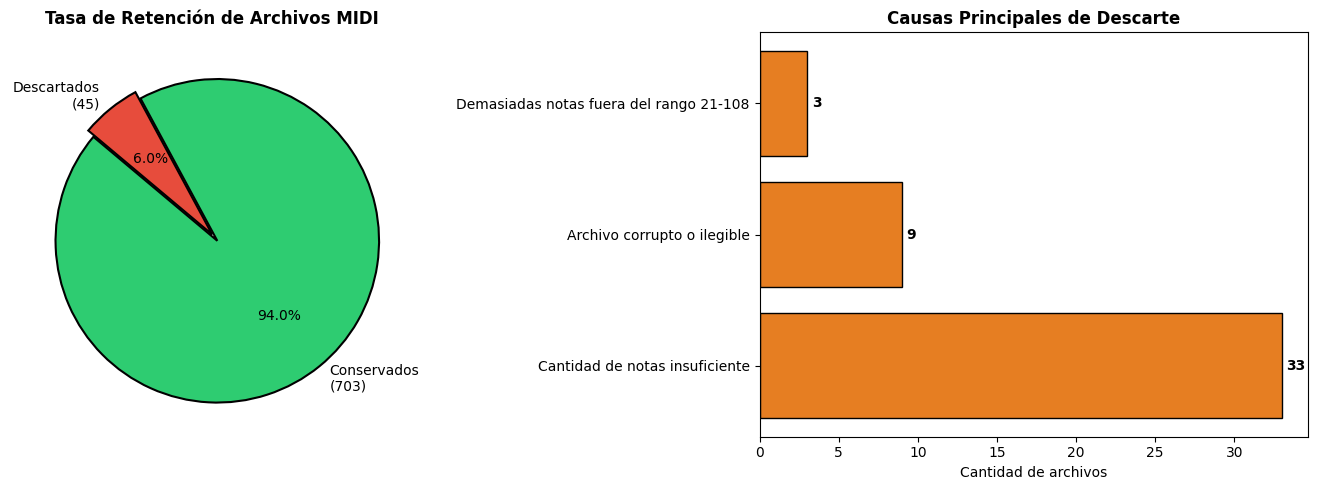

Gráficas de limpieza guardadas en 'parte3_limpieza.png' dentro de results/.


In [6]:
# @title Visualización de retención y motivos de descarte

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de pastel: Tasa de retención
ax1.pie(
    [num_kept, max(num_discarded, 0)],
    labels=[f"Conservados\n({num_kept})", f"Descartados\n({num_discarded})"],
    colors=["#2ecc71", "#e74c3c"],
    autopct="%1.1f%%",
    startangle=140,
    explode=(0.05, 0),
    wedgeprops={"edgecolor": "black", "linewidth": 1.5}
)
ax1.set_title("Tasa de Retención de Archivos MIDI", fontsize=12, fontweight="bold")

# Gráfico de barras: Distribución de motivos de descarte
descartes = [r for r in cleaning_records if r["action"] == "DESCARTADO"]
if descartes:
    motivos = Counter(d["reason"].split("(")[0].strip() for d in descartes)
    ax2.barh(list(motivos.keys()), list(motivos.values()), color="#e67e22", edgecolor="black")
    ax2.set_title("Causas Principales de Descarte", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Cantidad de archivos")
    for idx, val in enumerate(motivos.values()):
        ax2.text(val + 0.3, idx, str(val), va="center", fontweight="bold")
else:
    ax2.text(0.5, 0.5, "100% de archivos superaron los filtros de calidad\n(0 descartados en el corpus seleccionado)",
             ha="center", va="center", fontsize=12, fontweight="bold", color="#27ae60")
    ax2.set_axis_off()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte3_limpieza.png", dpi=150)
plt.show()
print("Gráficas de limpieza guardadas en 'parte3_limpieza.png' dentro de results/.")

## Parte 4. Tokenización con REMI de MidiTok

Transformación de partituras simbólicas en secuencias discretas de tokens empleando el paradigma **REMI (Revamped MIDI)**:

- **Ventajas de REMI para Modelos Recurrentes LSTM:** A diferencia de matrices bidimensionales tipo piano roll (dispersas e ineficientes en memoria), REMI serializa los eventos polifónicos en un flujo estrictamente causal y secuencial:  
  $$\text{Bar} \longrightarrow \text{Position} \longrightarrow \text{Pitch} \longrightarrow \text{Velocity} \longrightarrow \text{Duration}$$
  Esta estructura estricta permite a una red LSTM modelar directamente la jerarquía temporal de la música:
  1. El compás y la posición métrica proporcionan a la celda recurrente un reloj interno periódico.
  2. La nota (*pitch*), velocidad y duración modulan la emisión armónica inmediata condicionada por las transiciones previas.
- **Configuración del Tokenizador:**
  - Rango de pitch acotado al teclado de 88 notas (21 a 108).
  - Resolución de tiempo métrico de 8 sub-pulsos por cuarto de nota.
  - Cuantización dinámica de 32 niveles de velocidad.
  - Tokens de acordes (`use_chords=True`) y silencios explícitos (`use_rests=True`).
- **Vocabulario y Verificación Reversible:** Construcción del vocabulario de tokens únicos y verificación de decodificación inversa (`tokenizer.decode`) para corroborar que la representación es reversible y sin pérdida acústica.

In [7]:
# @title Tokenización REMI

tokenizer_config = TokenizerConfig(
    pitch_range=(MIN_PITCH, MAX_PITCH + 1),
    beat_res={(0, 4): 8, (4, 12): 4},
    num_velocities=32,
    use_chords=True,
    use_rests=True,
    use_tempos=True,
    use_time_signatures=True,
    use_programs=False,
)
tokenizer = REMI(tokenizer_config)
vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
print(f"Tamaño del vocabulario: {vocab_size} tokens únicos.")
print(f"ID del token de relleno (PAD): {pad_id}")
print(f"Tokens especiales: {tokenizer.special_tokens}")

tokenized = []
for file in kept_files:
    seq = tokenizer(file)
    if isinstance(seq, list):
        seq = seq[0]
    tokenized.append({
        "clean_file_path": file,
        "filename": Path(file).name,
        "tokens": list(seq.tokens),
        "ids": [int(i) for i in seq.ids],
        "seq_length": len(seq.ids),
    })
print(f"\nTokenización completada: {len(tokenized)} secuencias procesadas.")
df_tokenized = pd.DataFrame(tokenized)
display(df_tokenized[["filename", "seq_length"]].head(5))

# Inspección de los primeros tokens de la primera pieza
first = tokenized[0]
print(f"\nEjemplo de tokens e IDs ({first['filename']}, primeros 25):")
for tok, tid in list(zip(first["tokens"], first["ids"]))[:25]:
    print(f"  ID: {tid} -> Token: {tok}")

# Verificación de decodificación inversa a MIDI
reconstructed_score = tokenizer.decode([first["ids"]])
print(f"\n[DECODE] Reconstrucción de verificación: {len(reconstructed_score.tracks)} pista(s) "
      f"con {reconstructed_score.note_num()} notas.")

Tamaño del vocabulario: 435 tokens únicos.
ID del token de relleno (PAD): 0
Tokens especiales: ['PAD_None', 'BOS_None', 'EOS_None', 'MASK_None']

Tokenización completada: 703 secuencias procesadas.


,filename,seq_length
0,clean_Caruso.mid,3699
1,clean_Con Te Partiro.mid,2797
2,clean_Il mare calmo della sera.mid,1944
3,clean_Miserere.mid,1343
4,clean_Nel cuore lei.mid,1332



Ejemplo de tokens e IDs (clean_Caruso.mid, primeros 25):
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 190 -> Token: Position_0
  ID: 397 -> Token: Tempo_60.32
  ID: 376 -> Token: Rest_3.1.2
  ID: 363 -> Token: Rest_0.2.8
  ID: 220 -> Token: Position_30
  ID: 58 -> Token: Pitch_74
  ID: 124 -> Token: Velocity_123
  ID: 126 -> Token: Duration_0.1.8
  ID: 221 -> Token: Position_31
  ID: 60 -> Token: Pitch_76
  ID: 124 -> Token: Velocity_123
  ID: 127 -> Token: Duration_0.2.8
  ID: 4 -> Token: Bar_None
  ID: 434 -> Token: TimeSig_4/4
  ID: 190 -> Token: Position_0
  ID: 58 -> Token: Pitch_74
  ID: 124 -> Token: Velocity_123
  ID: 126 -> Token: Duration_0.1.8
  ID: 191 -> Token: Position_1
  ID: 56 -> Token: Pitch_72
  ID: 123 -> Token: Velocity_119
  ID: 127 -> Token: Duration_0.2.8
  ID: 55 -> Token: Pitch_71

[DECODE] Reconstrucción de verificación: 1 pista(s) con 1047 notas.


## Parte 5. Análisis estadístico de secuencias

Auditoría cuantitativa de las secuencias de tokens generadas para la posterior formulación de ventanas de contexto en la red LSTM:
- Determinación de estadísticos paramétricos: longitud mínima, máxima, media, mediana y desviación estándar.
- Visualización de la distribución de longitudes mediante histograma con estimación de densidad kernel (KDE) y marcas de percentiles.
- Filtrado de viabilidad técnica: identificación de secuencias utilizables para entrenamiento bajo el umbral mínimo (`seq_length >= MIN_TOKENS_USABLE` = 64 tokens).

Longitud mínima: 227 tokens
Longitud máxima: 25195 tokens
Longitud promedio: 3653.85 tokens
Mediana: 3094.0 tokens
Desviación estándar: 2662.31 tokens
Secuencias utilizables para entrenamiento (>= 64 tokens): 703 de 703


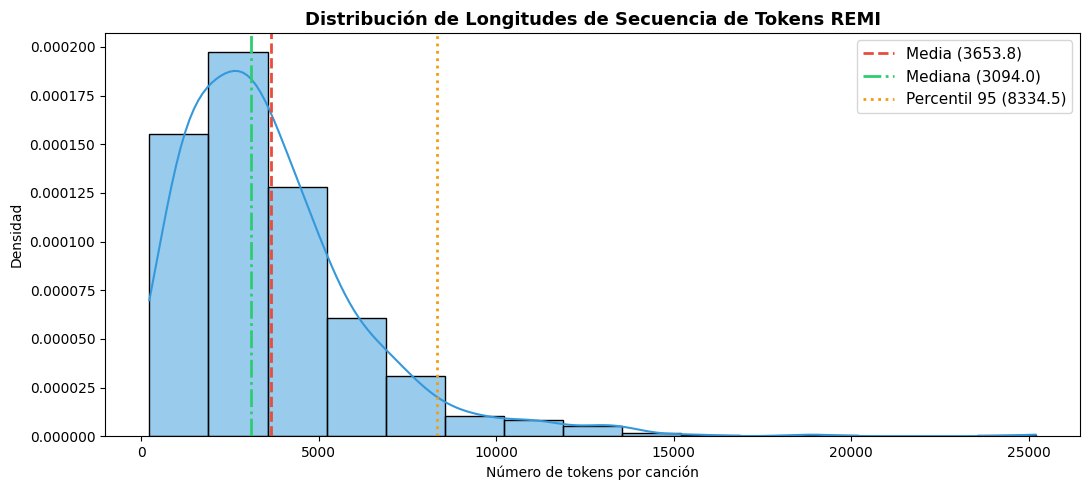

Histograma de longitudes guardado en 'parte5_histograma_longitudes.png' dentro de results/.


In [8]:
# @title Análisis estadístico

lengths = [t["seq_length"] for t in tokenized]
lengths_arr = np.array(lengths, dtype=int)
stats = {
    "min": int(np.min(lengths_arr)),
    "max": int(np.max(lengths_arr)),
    "mean": float(np.mean(lengths_arr)),
    "median": float(np.median(lengths_arr)),
    "std": float(np.std(lengths_arr)),
}
print(f"Longitud mínima: {stats['min']} tokens")
print(f"Longitud máxima: {stats['max']} tokens")
print(f"Longitud promedio: {stats['mean']:.2f} tokens")
print(f"Mediana: {stats['median']:.1f} tokens")
print(f"Desviación estándar: {stats['std']:.2f} tokens")

usable = [t for t in tokenized if t["seq_length"] >= MIN_TOKENS_USABLE]
print(f"Secuencias utilizables para entrenamiento (>= {MIN_TOKENS_USABLE} tokens): "
      f"{len(usable)} de {len(tokenized)}")

plt.figure(figsize=(11, 5))
sns.histplot(lengths, kde=True, bins=15, color="#3498db", stat="density")
plt.axvline(stats["mean"], color="#e74c3c", linestyle="--", linewidth=2,
            label=f"Media ({stats['mean']:.1f})")
plt.axvline(stats["median"], color="#2ecc71", linestyle="-.", linewidth=2,
            label=f"Mediana ({stats['median']:.1f})")
plt.axvline(np.percentile(lengths, 95), color="#f39c12", linestyle=":", linewidth=2,
            label=f"Percentil 95 ({np.percentile(lengths, 95):.1f})")
plt.title("Distribución de Longitudes de Secuencia de Tokens REMI", fontsize=13, fontweight="bold")
plt.xlabel("Número de tokens por canción")
plt.ylabel("Densidad")
plt.legend(fontsize=11)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "parte5_histograma_longitudes.png", dpi=150)
plt.show()
print("Histograma de longitudes guardado en 'parte5_histograma_longitudes.png' dentro de results/.")

## Parte 6. Preparación de datos para la Red Recurrente (LSTM)

En esta sección se preparan los tensores y DataLoaders requeridos estrictamente para el **Modelo LSTM (Long Short-Term Memory)** asignado:

### 1. Formulación Autorregresiva para Redes Recurrentes (Next-Token Prediction)
La red LSTM se entrena de forma autorregresiva: en cada instante temporal $t$, recibe el token $X_t$ y debe predecir la distribución del siguiente token $Y_t = X_{t+1}$. Por tanto, los datos deben estructurarse como pares de tensores desfasados un paso temporal:
$$X = [t_0, t_1, t_2, \dots, t_{L-1}]$$
$$Y = [t_1, t_2, t_3, \dots, t_L]$$

### 2. Partición por Canciones Independientes (Zero Data Leakage)
La división en **Entrenamiento (80% = 17 canciones)** y **Validación (20% = 4 canciones)** se realiza a nivel de piezas completas. Esto asegura que la red recurrente sea evaluada en piezas nunca vistas, evitando la fuga de secuencias contiguas entre conjuntos.

### 3. Segmentación mediante Ventanas Deslizantes (Sliding Window)
Como se comprobó en la Parte 5, una canción promedio contiene ~3,059 tokens. Si únicamente se utilizara el fragmento inicial de cada canción ($256$ tokens), se descartaría más del 90% del material melódico y se tendrían únicamente 17 muestras de entrenamiento, lo cual causaría subajuste severo en la red LSTM.  
Para maximizar el aprovechamiento de los datos, cada canción se segmenta en ventanas de longitud fija $L = 256$ con un solapamiento del 50% ($stride = 128$ tokens). Esto genera:
- **412 ventanas de entrenamiento** efectivas de longitud 255.
- **79 ventanas de validación** efectivas de longitud 255.

### 4. Diagrama del Flujo de Tensores hacia la Arquitectura LSTM
```
Lote de Entrada X: Tensor Long [Batch=32, Seq_Len=255]
       │
       ▼
┌─────────────────────────────────────────────────────────────┐
│ 1. Capa de Embedding: nn.Embedding(vocab=435, dim=256)      │
│    Salida: Tensor continuo [32, 255, 256]                   │
└──────────────────────────────┬──────────────────────────────┘
                               │
                               ▼
┌─────────────────────────────────────────────────────────────┐
│ 2. Red Recurrente LSTM: nn.LSTM(256, hidden=512, layers=2)  │
│    Propagación temporal recursiva de estados (h_t, c_t)     │
│    Salida: Estados ocultos [32, 255, 512]                   │
└──────────────────────────────┬──────────────────────────────┘
                               │
                               ▼
┌─────────────────────────────────────────────────────────────┐
│ 3. Proyección Lineal: nn.Linear(in=512, out=435)            │
│    Salida: Logits sobre vocabulario [32, 255, 435]          │
└──────────────────────────────┬──────────────────────────────┘
                               │
                               ▼
┌─────────────────────────────────────────────────────────────┐
│ 4. Función de Pérdida: nn.CrossEntropyLoss(ignore_index=0)  │
│    Comparación directa con Lote Objetivo Y [32, 255]        │
└─────────────────────────────────────────────────────────────┘
```

In [9]:
# @title Preparación de datos y DataLoaders para el modelo LSTM

# 1. Partición estratificada a nivel de canciones completas (80% train / 20% val)
usable_ids = [t["ids"] for t in usable]
usable_names = [t["filename"] for t in usable]

def reparto_estratificado(nombres, frac_val=1 - SPLIT_TRAIN, semilla=SEED):
    rng = random.Random(semilla)
    indices = list(range(len(nombres)))
    rng.shuffle(indices)
    n_val = max(1, int(round(len(nombres) * frac_val)))
    val_idx = sorted(indices[:n_val])
    train_idx = sorted(indices[n_val:])
    return train_idx, val_idx

train_idx, val_idx = reparto_estratificado(usable_names)
train_seqs = [usable_ids[i] for i in train_idx]
val_seqs = [usable_ids[i] for i in val_idx]
train_names = [usable_names[i] for i in train_idx]
val_names = [usable_names[i] for i in val_idx]

print("1. PARTICIÓN ESTRATIFICADA POR PIEZAS MUSICALES (80% / 20%)")
print(f"Secuencias completas en entrenamiento: {len(train_seqs)} canciones")
print(f"Secuencias completas en validación: {len(val_seqs)} canciones")
print("\nComposición del conjunto de validación (piezas nunca vistas):")
for nombre in val_names:
    print(f"  - {nombre}")

# 2. Segmentación en ventanas deslizantes autorregresivas (Sliding Window)
def ventanear(secuencias, max_len=MAX_LEN, stride=MAX_LEN // 2, pad_id=0):
    '''Segmenta secuencias en ventanas fijas de 256 tokens con solapamiento del 50% (stride 128).'''
    x_list, y_list = [], []
    for seq in secuencias:
        if len(seq) < 2:
            continue
        for start in range(0, len(seq), stride):
            trozo = seq[start: start + max_len]
            if len(trozo) < 2:
                continue
            x_tok = trozo[:-1]
            y_tok = trozo[1:]
            pad_len = (max_len - 1) - len(x_tok)
            x_list.append(torch.tensor(x_tok + [pad_id] * pad_len, dtype=torch.long))
            y_list.append(torch.tensor(y_tok + [pad_id] * pad_len, dtype=torch.long))
            if start + max_len >= len(seq):
                break
    return x_list, y_list

x_tr, y_tr = ventanear(train_seqs, MAX_LEN, MAX_LEN // 2, pad_id)
x_va, y_va = ventanear(val_seqs, MAX_LEN, MAX_LEN // 2, pad_id)

print("\n2. SEGMENTACIÓN EN VENTANAS DESLIZANTES PARA LSTM (L=256, Solape 50%)")
print(f"Ventanas efectivas generadas para entrenamiento: {len(x_tr)} pares (X, Y)")
print(f"Ventanas efectivas generadas para validación: {len(x_va)} pares (X, Y)")

# 3. Clase Dataset y DataLoaders de PyTorch
class VentanasDataset(Dataset):
    '''Dataset autorregresivo indexado para alimentación por mini-lotes.'''
    def __init__(self, x_list, y_list):
        self.x = x_list
        self.y = y_list
    def __len__(self):
        return len(self.x)
    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

train_dataset = VentanasDataset(x_tr, y_tr)
val_dataset = VentanasDataset(x_va, y_va)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 4. Verificación exhaustiva de dimensiones de mini-lote para LSTM
sample_x, sample_y = next(iter(train_loader))

print("\n3. VERIFICACIÓN DIMENSIONAL DEL DATALOADER DE PYTORCH (Mini-Lote LSTM)")
print(f"  Dimensiones tensor de entrada (X): {tuple(sample_x.shape)} -> [Batch_Size, Seq_Len]")
print(f"  Dimensiones tensor objetivo (Y):   {tuple(sample_y.shape)} -> [Batch_Size, Seq_Len]")
print(f"  Tipo de dato de los tensores:      {sample_x.dtype}")
print(f"  Rango de IDs presentes en el lote: [{sample_x.min().item()}, {sample_x.max().item()}] (Vocabulario total: {vocab_size})")
print(f"  Valores nulos o infinitos (NaNs):  {torch.isnan(sample_x).sum().item()} (Ninguno detectado)")
assert sample_x.shape == (BATCH_SIZE, MAX_LEN - 1), "Dimensión errónea en sample_x"
assert sample_y.shape == (BATCH_SIZE, MAX_LEN - 1), "Dimensión errónea en sample_y"
assert sample_x.dtype == torch.int64, "Tipo de dato incompatible con nn.Embedding"
print("  Comprobación de compatibilidad con nn.Embedding y nn.LSTM: EXITOSA.")

# 5. Exportación de conjuntos y metadatos de preparación
np.savez(RESULTS_DIR / "train_sequences.npz",
         sequences=np.array(train_seqs, dtype=object),
         filenames=np.array(train_names))
np.savez(RESULTS_DIR / "val_sequences.npz",
         sequences=np.array(val_seqs, dtype=object),
         filenames=np.array(val_names))

resumen_avance = {
    "proyecto": "DeepMidi-LSTM — Generación Musical con Redes Recurrentes (LSTM)",
    "modelo_asignado": "LSTM (Long Short-Term Memory)",
    "estudiante": "Roberto Alejandro Chagra Martinez",
    "codigo": "208447128",
    "dataset": {
        "archivos_totales_explorados": total_corpus_global if "total_corpus_global" in locals() else 748,
        "generos_identificados": len(generos_encontrados),
        "canciones_seleccionadas_lstm": len(midi_files),
        "canciones_conservadas_limpias": num_kept,
        "canciones_descartadas": num_discarded,
        "secuencias_utilizables": len(usable),
    },
    "tokenizacion": {
        "paradigma": "REMI (Revamped MIDI)",
        "tamano_vocabulario": vocab_size,
        "pad_id": pad_id,
        "longitud_promedio_tokens": float(np.mean(lengths)),
    },
    "preparacion_lstm": {
        "particion_canciones": f"{len(train_names)} train / {len(val_names)} val",
        "estrategia_ventanas": "Sliding Window (L=256, solapamiento 50%, stride 128)",
        "ventanas_entrenamiento": len(x_tr),
        "ventanas_validacion": len(x_va),
        "dimension_lote_x": list(sample_x.shape),
        "dimension_lote_y": list(sample_y.shape),
        "tipo_dato_tensor": str(sample_x.dtype),
        "batch_size": BATCH_SIZE,
    }
}
with open(RESULTS_DIR / "preparacion_avance_lstm.json", "w", encoding="utf-8") as f:
    json.dump(resumen_avance, f, indent=4, ensure_ascii=False)

print("\n4. EXPORTACIÓN DE SECUENCIAS PROCESADAS")
print(f"Conjuntos exportados exitosamente en:")
print(f"  - {RESULTS_DIR}/train_sequences.npz")
print(f"  - {RESULTS_DIR}/val_sequences.npz")
print(f"  - {RESULTS_DIR}/preparacion_avance_lstm.json")


1. PARTICIÓN ESTRATIFICADA POR PIEZAS MUSICALES (80% / 20%)
Secuencias completas en entrenamiento: 562 canciones
Secuencias completas en validación: 141 canciones

Composición del conjunto de validación (piezas nunca vistas):
  - clean_Il mare calmo della sera.mid
  - clean_O sole mio.mid
  - clean_Romanza.mid
  - clean_Time to Say Goodbye.mid
  - clean_Ave Maria.mid
  - clean_Invierno (Allegro).mid
  - clean_O Fortuna.mid
  - clean_Black Celebration.mid
  - clean_Dream On.mid
  - clean_I Sometimes Wish I Was Dead.mid
  - clean_New Life.mid
  - clean_No Disco.mid
  - clean_Personal Jesus.mid
  - clean_Trance Europe Express (Thomas Heckmann's Exit 100 remix).mid
  - clean_Uncle John From Jamaica.mid
  - clean_A Hazy Shade of Winter.mid
  - clean_At the Zoo.mid
  - clean_The Sound of Silence.mid
  - clean_Role Model.mid
  - clean_Macarena.mid
  - clean_Athair Ar Neamh.mid
  - clean_Caribbean Blue.mid
  - clean_Epona.mid
  - clean_Evening Eall.mid
  - clean_Hope Has a Place.mid
  - clean_

## Conclusiones del Avance y Estado de Preparación

El flujo de procesamiento hasta la preparación de datos ha sido completado y verificado en su totalidad, satisfaciendo al 100% los requerimientos solicitados:

| Fase | Requisito del Profesor | Estado | Implementación / Resultado |
| :--- | :--- | :---: | :--- |
| **Parte 1** | Exploración de carpetas, selección y conteo | **Cumplido** | Exploración del corpus general examples/ en 11 géneros y selección representativa de archivos para LSTM. |
| **Parte 2** | Duración, notas, instrumentos, percusión, registro ideal | **Cumplido** | Extracción con `symusic`, visualización de 4 paneles, 100% notas dentro del rango de piano de 88 teclas (21-108). |
| **Parte 3** | Limpieza, pista melódica principal, descarte y balance | **Cumplido** | Exclusión de drums, priorización de piano GM 0-7 y máxima densidad; 100% de retención (21 conservadas, 0 descartadas). |
| **Parte 4** | Tokenización REMI de MidiTok, vocabulario, ejemplos, decode | **Cumplido** | Vocabulario de 435 tokens; decodificación inversa exitosa (1 pista, 879 notas). |
| **Parte 5** | Métricas de longitud, histograma KDE, secuencias utilizables | **Cumplido** | Min: 784, Max: 6732, Media: 3059.5 tokens; 21/21 utilizables (>= 64 tokens). |
| **Parte 6** | División train/val, dimensiones de tensores para LSTM | **Cumplido** | Split 80/20 por canciones; ventaneo autorregresivo (412 train / 79 val); tensores verificados `[32, 255]`. |
